# Pipeline de Mercado B3
Cotações de fechamento dos últimos 5 anos: Ibovespa e principais ações.

In [13]:
import yfinance as yf
import matplotlib.pyplot as plt
import polars as pl

In [14]:
# Define a lista de tickers (adicionando ".SA" para a B3)
tickers = {
    'Ibovespa': '^BVSP',
    'VALE3': 'VALE3.SA',
    'PETR4': 'PETR4.SA',
    'ITUB4': 'ITUB4.SA',
    'BBDC4': 'BBDC4.SA',
    'BBAS3': 'BBAS3.SA'
}

In [15]:
# Obtém os dados dos últimos 5 anos para todos os tickers (yfinance retorna pandas)
data = yf.download(list(tickers.values()), period='5y')

# Extrai apenas as colunas de Fechamento ('Close') e converte para polars,
# mantendo o índice de datas como coluna 'Date'
close_data = pl.from_pandas(data['Close'].reset_index())

# Renomeia as colunas para os nomes amigáveis
inv_tickers = {v: k for k, v in tickers.items()}
close_data = close_data.rename(inv_tickers)

[                       0%                       ]

[*********************100%***********************]  6 of 6 completed


In [16]:
# Exibe a tabela com os últimos registros
print("Últimas cotações de fechamento (R$ / Pontos para Ibovespa):")
display(close_data.tail())

Últimas cotações de fechamento (R$ / Pontos para Ibovespa):


Date,BBAS3,BBDC4,ITUB4,PETR4,VALE3,Ibovespa
datetime[ms],f64,f64,f64,f64,f64,f64
2026-10-29 00:00:00,16.459999,14.140215,39.52142,52.200001,60.049999,169186.0
2026-10-30 00:00:00,16.469999,13.840633,38.671818,52.709999,62.02,167922.0
2026-11-03 00:00:00,16.190001,13.561026,38.490002,50.709999,60.25,165529.0
2026-11-04 00:00:00,16.49,14.06,39.709999,47.119999,62.349998,167564.0
2026-11-05 00:00:00,16.43,13.88,39.709999,46.709999,62.720001,166634.03125


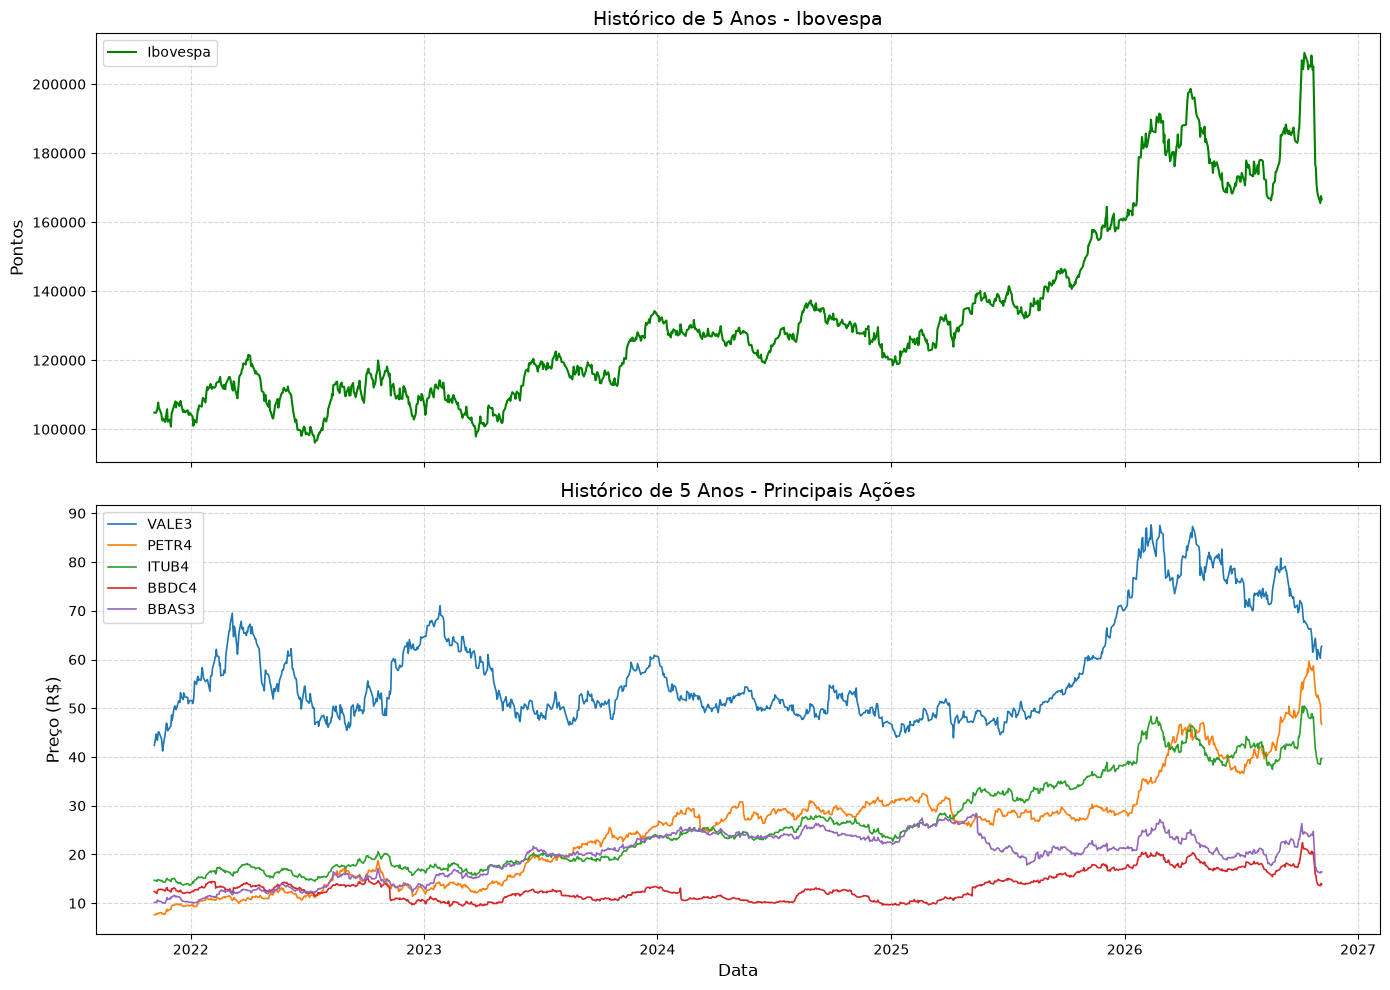

In [17]:
# Ibovespa (escala muito maior) em gráfico separado das ações
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True)
dates = close_data['Date'].to_list()

# Gráfico do Ibovespa
ax1.plot(dates, close_data['Ibovespa'].to_list(), label='Ibovespa', color='green', linewidth=1.5)
ax1.set_title('Histórico de 5 Anos - Ibovespa', fontsize=14)
ax1.set_ylabel('Pontos', fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend()

# Gráfico das Ações
for stock in ['VALE3', 'PETR4', 'ITUB4', 'BBDC4', 'BBAS3']:
    ax2.plot(dates, close_data[stock].to_list(), label=stock, linewidth=1.2)
ax2.set_title('Histórico de 5 Anos - Principais Ações', fontsize=14)
ax2.set_xlabel('Data', fontsize=12)
ax2.set_ylabel('Preço (R$)', fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()